# Overlap width scan at fixed $h=0.15$

This dated progress snapshot shows only complete eight-disorder ensembles.
The original scan covers $L=4,6$, $\Gamma=0.60,0.65,0.70,0.85,1.00$;
the fine scan adds $L=4$ fields $0.55,0.56,\ldots,0.70$ and $L=6$ fields
$0.55,\ldots,0.60$, reusing existing fields. Missing ensembles remain pending.

The periodic kagome Hamiltonian is
$$H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-0.15\sum_iZ_i-\Gamma\sum_iX_i,$$
with independent AF bonds $K_{ij}\sim U(0.5,1.5)$, stored as $J_{ij}=-K_{ij}$.
NumPy `default_rng(SeedSequence([20261027,L,sample_id,1]))` draws the quenched
bonds in bond-list order. IDs 60000–60007 have equal weight and are shared
across fields and guides at each size; different sizes have different bonds.
No samples are selected using distribution width.

Four independently branching GFMC populations estimate overlap moments using
cross-population products. Main runs use 512 walkers per population,
equilibration and forward times 16, eight cycles and two repeats. Repeats are
averaged within each disorder before averaging disorders.

The plotted width is $\sigma_q=\sqrt{[\langle q^2\rangle]_J-[\langle q\rangle]_J^2}$.
It is computed from measured moments; it does not reconstruct a full $P(q)$.
The existing `preliminary_disorder_overlap.ipynb` contains measured histograms
at $\Gamma=0.60,0.65$. Broader moment-based widths at other fields require full
histogram measurements before their shapes can be displayed.

Capped error bars are one disorder standard error, using a delete-one-disorder
jackknife for widths and $s_J/\sqrt8$ for the mean overlap. They exclude mixing,
population and projection bias. All ancestry alarms remain in the averages.
Results remain preliminary; broadening alone does not establish glassiness.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
folder=root/'data/kagome/ltfim_disorder_scaling_v1/scan_progress/20261103T032310Z'
snapshot=json.loads((folder/'snapshot.json').read_text())
for name,digest in snapshot['input_sha256'].items():
    assert hashlib.sha256((folder/name).read_bytes()).hexdigest()==digest
rows=json.loads((folder/'records.json').read_text())['rows']
groups=defaultdict(list)
for item in rows:
    r=item['record'];t=r['task']
    if t['audit']=='main':
        groups[(item['campaign'],t['L'],t['gamma'],t['kind'])].append(item)
def width(x):
    variance=x[:,1].mean()-x[:,0].mean()**2
    assert variance>=-1e-12
    return np.sqrt(max(0.,variance))
complete=[];coverage=[]
for (campaign,L,g,kind),items in sorted(groups.items()):
    rs=[item['record'] for item in items]
    byid={sid:[r for r in rs if r['task']['sample_id']==sid] for sid in range(60000,60008)}
    done=[sid for sid,records in byid.items() if len(records)==2 and {r['task']['repeat'] for r in records}=={0,1}]
    coverage.append([campaign,L,g,kind,len(done),len(rs)])
    if len(done)!=8 or len(rs)!=16:
        continue
    x=np.array([[np.mean([r[k] for r in byid[sid]]) for k in ['q','q2']] for sid in done])
    for item in items:
        r=item['record']
        with np.load(folder/item['raw_file']) as raw:
            if 'mass' in r:
                q=np.array(r['q_grid']);p=np.array(r['mass'])
                np.testing.assert_allclose([q@p,q**2@p],[r['q'],r['q2']],atol=1e-12)
            else:
                from itertools import combinations
                m=raw['magnetization_cycles'].mean(0);p=raw['pair_cycles'].mean(0)
                measured=[np.mean([np.mean(a[i]*a[j]) for i,j in combinations(range(4),2)]) for a in [m,p]]
                np.testing.assert_allclose(measured,[r['q'],r['q2']],atol=1e-12)
    jack=np.array([width(np.delete(x,i,axis=0)) for i in range(8)])
    within=float(np.mean(x[:,1]-x[:,0]**2));between=float(x[:,0].var())
    np.testing.assert_allclose(within+between,width(x)**2,atol=1e-12)
    complete.append(dict(campaign=campaign,L=L,gamma=g,kind=kind,mean_q=float(x[:,0].mean()),
        mean_q_se=float(x[:,0].std(ddof=1)/np.sqrt(8)),width=float(width(x)),
        width_se=float(np.sqrt(7/8*np.sum((jack-jack.mean())**2))),
        within_disorder_variance=within,between_disorder_variance=between,
        ancestry_alarms=sum(r['ancestry_alarm'] for r in rs),runs=len(rs)))
def table(headers,values):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
        '\n'.join('| '+' | '.join(map(str,row))+' |' for row in values)))
print('Snapshot:',snapshot['created_utc'])
table(['Campaign','L','Gamma','Guide','Disorders with both repeats / 8','Main runs / 16'],coverage)
for campaign in ['original','fine']:
    status=json.loads((folder/campaign/'parallel_status.json').read_text())
    print(campaign,{k:status.get(k) for k in ['state','completed_fits','planned_fits','completed_runs','updated_unix','failures']})


Snapshot: 2026-11-03T03:23:10.611834+00:00


| Campaign | L | Gamma | Guide | Disorders with both repeats / 8 | Main runs / 16 |
| --- | --- | --- | --- | --- | --- |
| fine | 4 | 0.55 | jastrow | 1 | 2 |
| fine | 4 | 0.55 | rbm_2 | 1 | 2 |
| original | 4 | 0.6 | jastrow | 8 | 16 |
| original | 4 | 0.6 | rbm_2 | 8 | 16 |
| original | 4 | 0.65 | jastrow | 8 | 16 |
| original | 4 | 0.65 | rbm_2 | 8 | 16 |
| original | 4 | 0.7 | jastrow | 8 | 16 |
| original | 4 | 0.7 | rbm_2 | 8 | 16 |
| original | 4 | 0.85 | jastrow | 8 | 16 |
| original | 4 | 0.85 | rbm_2 | 8 | 16 |
| original | 4 | 1.0 | jastrow | 4 | 8 |
| original | 4 | 1.0 | rbm_2 | 2 | 4 |

original {'state': 'running', 'completed_fits': 246, 'planned_fits': 320, 'completed_runs': 254, 'updated_unix': 1793676188.4233081, 'failures': []}
fine {'state': 'running', 'completed_fits': 30, 'planned_fits': 576, 'completed_runs': 14, 'updated_unix': 1793676166.819369, 'failures': []}


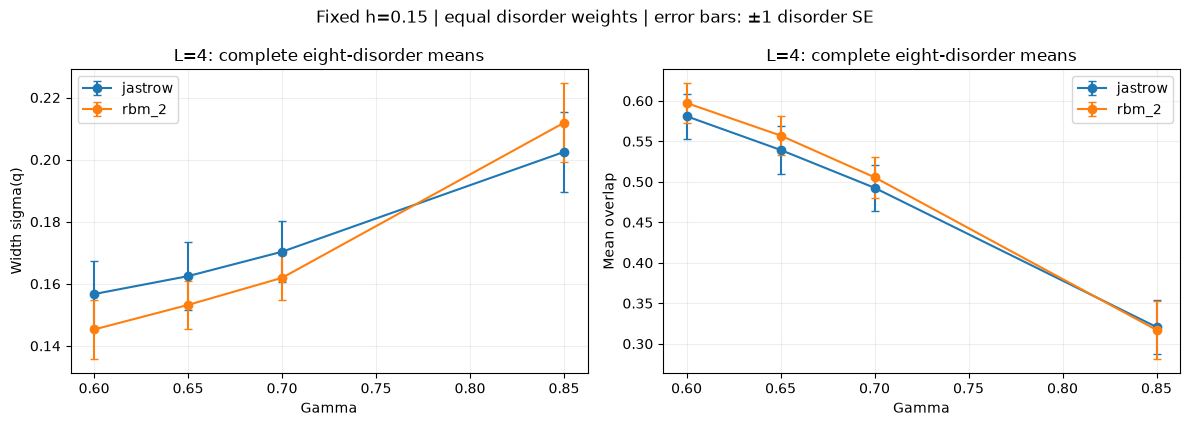

| L | Gamma | Guide | Width | Within variance | Between variance | Ancestry alarms / 16 |
| --- | --- | --- | --- | --- | --- | --- |
| 4 | 0.6 | jastrow | 0.1567 | 0.01914 | 0.00542 | 6 |
| 4 | 0.6 | rbm_2 | 0.1453 | 0.01690 | 0.00421 | 8 |
| 4 | 0.65 | jastrow | 0.1625 | 0.02040 | 0.00600 | 5 |
| 4 | 0.65 | rbm_2 | 0.1532 | 0.01927 | 0.00421 | 14 |
| 4 | 0.7 | jastrow | 0.1703 | 0.02336 | 0.00566 | 5 |
| 4 | 0.7 | rbm_2 | 0.1619 | 0.02164 | 0.00458 | 14 |
| 4 | 0.85 | jastrow | 0.2025 | 0.03303 | 0.00796 | 6 |
| 4 | 0.85 | rbm_2 | 0.2119 | 0.03576 | 0.00913 | 15 |

Complete fine-grid projected ensembles: 0
Raw hashes, moment reconstruction and variance decomposition verified.


In [2]:
sizes=sorted({r['L'] for r in complete})
assert sizes, 'No complete ensembles'
fig,axes=plt.subplots(len(sizes),2,figsize=(12,4.3*len(sizes)),squeeze=False)
for i,L in enumerate(sizes):
    for kind,color in [('jastrow','tab:blue'),('rbm_2','tab:orange')]:
        data=sorted([r for r in complete if r['L']==L and r['kind']==kind],key=lambda r:r['gamma'])
        for ax,key,error in [(axes[i,0],'width','width_se'),(axes[i,1],'mean_q','mean_q_se')]:
            ax.errorbar([r['gamma'] for r in data],[r[key] for r in data],
                yerr=[r[error] for r in data],fmt='o-',capsize=3,label=kind,color=color)
            ax.set(xlabel='Gamma',title=f'L={L}: complete eight-disorder means')
            ax.grid(alpha=.2);ax.legend()
    axes[i,0].set_ylabel('Width sigma(q)');axes[i,1].set_ylabel('Mean overlap')
fig.suptitle('Fixed h=0.15 | equal disorder weights | error bars: ±1 disorder SE')
fig.tight_layout()
for suffix in ['png','pdf']:
    fig.savefig(folder/('overlap_width_scan.'+suffix),dpi=180,bbox_inches='tight')
plt.show()
table(['L','Gamma','Guide','Width','Within variance','Between variance','Ancestry alarms / 16'],
    [[r['L'],r['gamma'],r['kind'],f"{r['width']:.4f}",f"{r['within_disorder_variance']:.5f}",
      f"{r['between_disorder_variance']:.5f}",r['ancestry_alarms']] for r in complete])
fine_complete=[r for r in complete if r['campaign']=='fine']
print('Complete fine-grid projected ensembles:',len(fine_complete))
(folder/'summary.json').write_text(json.dumps(dict(created_utc=snapshot['created_utc'],complete_ensembles=complete,
    coverage=coverage,ground_state_qualified=False),indent=2)+'\n')
print('Raw hashes, moment reconstruction and variance decomposition verified.')
